# Task 1: Artificial Neural Network (ANN) for Diabetes Prediction

## 1.1 Introduction

The objective of this project is to develop an Artificial Neural Network (ANN) using TensorFlow and Keras to predict whether a patient has diabetes.

We will use the Pima Indians Diabetes Dataset, which contains patient medical information and a target column named `Outcome`.

- `Outcome = 0`: The patient does not have diabetes.
- `Outcome = 1`: The patient has diabetes.

### Project workflow

1. Import the required libraries.
2. Load and inspect the dataset.
3. Clean missing or invalid zero values.
4. Separate input features and target.
5. Split the data into training and testing sets.
6. Scale the input features.
7. Build the ANN model.
8. Train the model for 50 epochs.
9. Evaluate the model using classification metrics.
10. Visualize training and validation performance.
11. Save the trained model.

**Expected output:** A trained ANN model, performance graphs, evaluation metrics, and a saved model file.


# Install the required libraries

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

print("All libraries imported successfully.")
print("TensorFlow Version:", tf.__version__)

All libraries imported successfully.
TensorFlow Version: 2.16.1


# Upload and read the CSV file

In [6]:
column_names = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

df = pd.read_csv(
    "pima-indians-diabetes.csv",
    header=None,
    names=column_names
)

## Display dataset information

In [7]:
print("Dataset Shape:")
print(df.shape)

Dataset Shape:
(768, 9)


In [8]:
print("\nFirst 5 Rows:")
display(df.head(5))


First 5 Rows:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [9]:
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


In [10]:

print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


## Check missing values

In [11]:
print("Missing Values Before Cleaning:")
print(df.isnull().sum())

zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

print("\nZero Values Before Cleaning:")

for col in zero_columns:
    print(f"{col}: {(df[col] == 0).sum()}")

Missing Values Before Cleaning:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Zero Values Before Cleaning:
Glucose: 5
BloodPressure: 35
SkinThickness: 227
Insulin: 374
BMI: 11


## Replace zero values with the median

In [12]:
df_clean = df.copy()

for col in zero_columns:
    median_value = df_clean.loc[
        df_clean[col] != 0, col
    ].median()

    df_clean[col] = df_clean[col].replace(
        0, median_value
    )

print("Zero values after cleaning:")

Zero values after cleaning:


In [13]:
for col in zero_columns:
    print(f"{col}: {(df_clean[col] == 0).sum()}")

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

Glucose: 0
BloodPressure: 0
SkinThickness: 0
Insulin: 0
BMI: 0

Missing values after cleaning:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


## Create X and y

In [14]:
X = df_clean.drop(columns=["Outcome"])
y = df_clean["Outcome"]

In [15]:


print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nInput Features:")
display(X.head())



Input Features Shape: (768, 8)
Target Shape: (768,)

Input Features:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148,72,35,125,33.6,0.627,50
1,1,85,66,29,125,26.6,0.351,31
2,8,183,64,29,125,23.3,0.672,32
3,1,89,66,23,94,28.1,0.167,21
4,0,137,40,35,168,43.1,2.288,33


In [16]:
print("\nTarget Values:")
display(y.head())


Target Values:


0    1
1    0
2    1
3    0
4    1
Name: Outcome, dtype: int64

## Perform the train-test split

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)
print("y_train Shape:", y_train.shape)
print("y_test Shape:", y_test.shape)

X_train Shape: (614, 8)
X_test Shape: (154, 8)
y_train Shape: (614,)
y_test Shape: (154,)


## Apply StandardScaler

In [18]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled Training Data Shape:", X_train_scaled.shape)
print("Scaled Testing Data Shape:", X_test_scaled.shape)



Scaled Training Data Shape: (614, 8)
Scaled Testing Data Shape: (154, 8)


In [19]:
print("\nFirst 5 Scaled Training Rows:")
print()
print(X_train_scaled[:5])


First 5 Scaled Training Rows:

[[-0.85135507 -1.05642747 -0.82674004 -1.91818693 -1.20336073 -0.76947697
   0.31079384 -0.79216928]
 [ 0.35657564  0.14439907  0.47777235 -0.22987447 -1.47019479 -0.41749769
  -0.11643851  0.56103382]
 [-0.5493724  -0.55608308 -1.15286813  1.23332967 -0.55533518  0.3597899
  -0.76486207 -0.70759409]
 [-0.85135507  0.81152492 -1.31593218 -0.00476614 -0.16143729 -0.40283188
   0.26231357 -0.36929331]
 [-1.15333775 -0.88964601 -0.66367599  1.12077551 -0.41556496  1.78237284
  -0.33762972 -0.96131967]]


## Create and compile the ANN

In [20]:
tf.keras.utils.set_random_seed(42)

ann_model = Sequential([
    Input(shape=(8,)),
    Dense(16, activation="relu"),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid")
])

ann_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)



In [21]:
ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 289 (1.13 KB)

 Trainable params: 289 (1.13 KB)

 Non-trainable params: 0 (0.00 B)

## Train the model

In [22]:
ann_history = ann_model.fit(
    X_train_scaled,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.4949 - loss: 0.7603 - val_accuracy: 0.5285 - val_loss: 0.7550
Epoch 2/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5906 - loss: 0.7034 - val_accuracy: 0.5528 - val_loss: 0.7009
Epoch 3/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6191 - loss: 0.6599 - val_accuracy: 0.6098 - val_loss: 0.6603
Epoch 4/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6415 - loss: 0.6273 - val_accuracy: 0.6260 - val_loss: 0.6294
Epoch 5/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6517 - loss: 0.6023 - val_accuracy: 0.6179 - val_loss: 0.6064
Epoch 6/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6599 - loss: 0.5832 - val_accuracy: 0.6179 - val_loss: 0.5891
Epoch 7/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6619 - loss: 0.5677 - val_accuracy: 0.6260 - val_loss: 0.5756
Epoch 8/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6578 - loss: 0.5549 - val_accuracy: 0.6260 - val_loss

## Accuracy graph

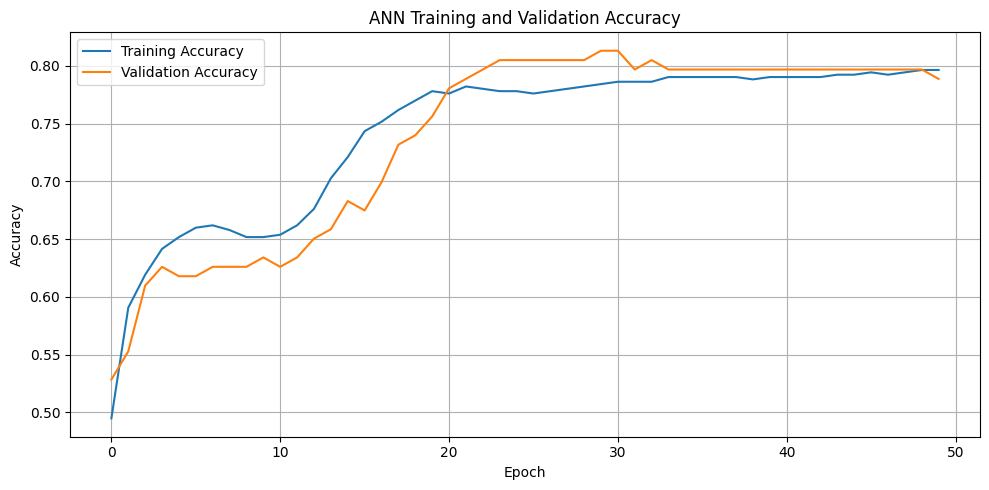

In [23]:
plt.figure(figsize=(10, 5))

plt.plot(
    ann_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    ann_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("ANN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Loss graph

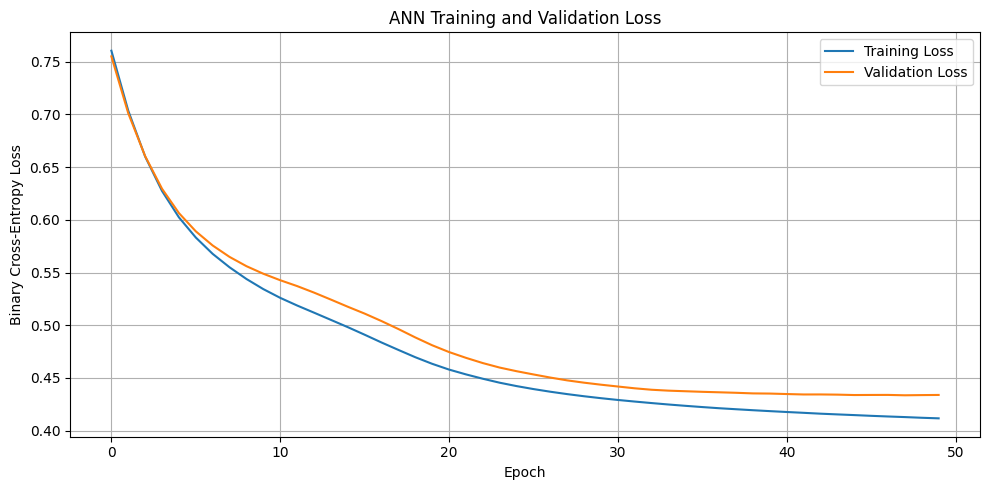

In [24]:
plt.figure(figsize=(10, 5))

plt.plot(
    ann_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    ann_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("ANN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Evaluate the model and print all metrics

In [25]:
test_loss, test_accuracy = ann_model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

y_probability = ann_model.predict(
    X_test_scaled,
    verbose=0
).ravel()

y_pred = (y_probability >= 0.5).astype(int)

In [26]:
ann_test_accuracy = accuracy_score(y_test, y_pred)



ann_precision = precision_score(
    y_test, y_pred, zero_division=0
)
ann_recall = recall_score(
    y_test, y_pred, zero_division=0
)
ann_f1 = f1_score(
    y_test, y_pred, zero_division=0
)


In [27]:
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {ann_test_accuracy:.4f}")
print(f"Precision: {ann_precision:.4f}")
print(f"Recall: {ann_recall:.4f}")
print(f"F1-Score: {ann_f1:.4f}")

Test Loss: 0.5167
Test Accuracy: 0.7143
Precision: 0.6087
Recall: 0.5185
F1-Score: 0.5600


In [28]:
ann_cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(ann_cm)


Confusion Matrix:
[[82 18]
 [26 28]]


## Plot the confusion matrix

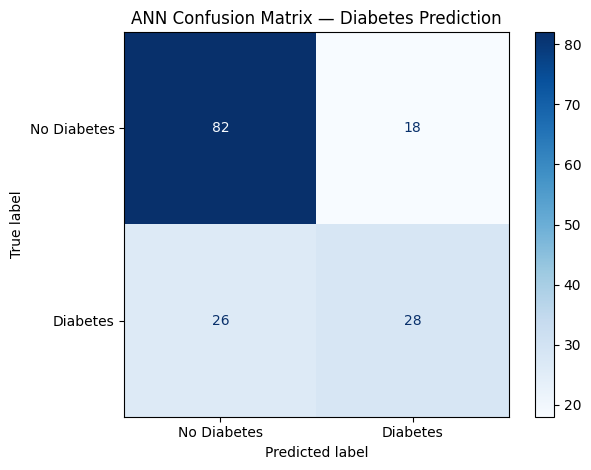

In [29]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Diabetes", "Diabetes"],
    cmap="Blues",
    values_format="d"
)

plt.title("ANN Confusion Matrix — Diabetes Prediction")
plt.tight_layout()
plt.show()

In [30]:
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Diabetes", "Diabetes"],
        zero_division=0
    )
)


Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.76      0.82      0.79       100
    Diabetes       0.61      0.52      0.56        54

    accuracy                           0.71       154
   macro avg       0.68      0.67      0.67       154
weighted avg       0.71      0.71      0.71       154



## Save the model

In [31]:
ann_model.save("ann_diabetes_model.h5")

print("ANN model saved successfully as ann_diabetes_model.h5")

ANN model saved successfully as ann_diabetes_model.h5


## Save the scaler

In [32]:
import joblib

joblib.dump(scaler, "ann_diabetes_scaler.pkl")

print("Scaler saved successfully.")

Scaler saved successfully.


## 1.13 Reflection and Conclusion

### 1. What does each layer do?

The input layer accepts eight patient features. The first hidden Dense layer has 16 neurons and uses ReLU activation to learn nonlinear relationships. The second hidden Dense layer has 8 neurons and learns additional combinations of features. The output layer has one neuron with Sigmoid activation to estimate the probability of the positive class.

### 2. Why did we choose 16 and 8 neurons?

The examination specifies hidden layers containing 16 and 8 neurons. This small architecture provides a straightforward starting point for binary classification. Different architectures could be tested to determine whether they improve generalization.

### 3. What does the Sigmoid output represent?

The Sigmoid function returns a number between 0 and 1. We interpret this as the model's estimated probability for the positive class. Using a threshold of 0.5, we classify the prediction as class 1 when the probability is at least 0.5; otherwise, it is class 0.

### 4. What did we learn?

This project demonstrated data cleaning, feature scaling, train-test splitting, ANN construction, model training, performance visualization, and classification evaluation. The accuracy, precision, recall, F1-score, and confusion matrix provide complementary information about the model's performance.

### 5. Conclusion

We implemented an ANN for diabetes classification using the Pima Indians Diabetes Dataset. The model was trained and evaluated on separate data, and the required model file was saved. The results describe performance on this dataset and do not establish that the model is suitable for clinical diagnosis.


## Task 2: Image Processing Using OpenCV

**Objective:** Process five images using OpenCV.

**Operations:**
1. Read and display the original images.
2. Resize each image to 128 × 128 pixels.
3. Convert each image to grayscale.
4. Apply Gaussian blur and Canny edge detection.
5. Detect contours and draw a green rectangle around the largest contour.
6. Display the results in a 5 × 5 grid and save the processed images.

## Import libraries

In [89]:
import os
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


## Load the five images

In [90]:
image_paths = []

for pattern in ["*.jpg", "*.jpeg", "*.png", "*.bmp"]:
    image_paths.extend(glob.glob(os.path.join("images", pattern)))

image_paths = sorted(set(image_paths))[:5]

images = []

for path in image_paths:
    image = cv2.imread(path)

    if image is not None:
        images.append((os.path.basename(path), image))

print("Images loaded:", len(images))

for name, image in images:
    print(name, "-> Shape:", image.shape)

if len(images) != 5:
    print("Please add five readable images to the images folder.")
else:
    print("All five images loaded successfully!")

Images loaded: 5
apple.jpg -> Shape: (5433, 3622, 3)
ball.png -> Shape: (655, 790, 3)
car.jpg -> Shape: (4000, 6000, 3)
dog.jpg -> Shape: (6016, 4016, 3)
flower.jpg -> Shape: (4668, 3112, 3)
All five images loaded successfully!


## Display the original images

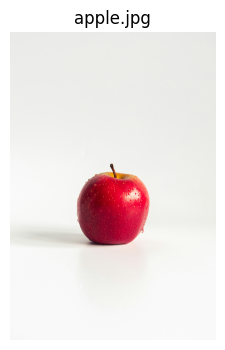

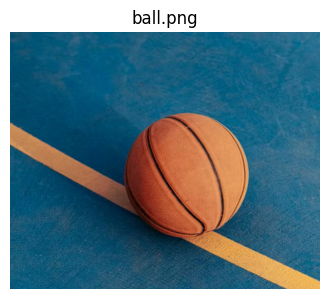

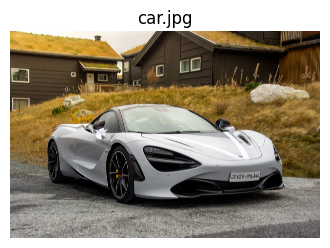

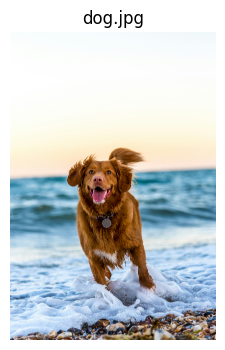

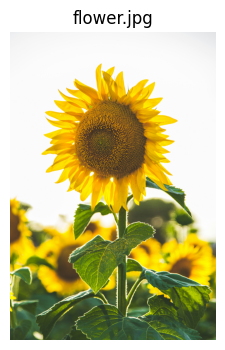

In [91]:
for name, image in images:
    plt.figure(figsize=(4, 4))
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(name)
    plt.axis("off")
    plt.show()

## Resize images to 128 × 128 pixels

In [92]:
resized_images = []

for name, image in images:
    resized = cv2.resize(image, (128, 128))
    resized_images.append((name, resized))

print("All images resized to 128 × 128 pixels.")

All images resized to 128 × 128 pixels.


## Convert images to grayscale

In [93]:
gray_images = []

for name, image in resized_images:
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    gray_images.append((name, gray))

print("Grayscale conversion completed.")

Grayscale conversion completed.


## Apply Gaussian blur

In [94]:
blurred_images = []

for name, gray in gray_images:
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    blurred_images.append((name, blurred))

print("Gaussian blur completed.")

Gaussian blur completed.


## Detect edges using Canny

In [95]:
edge_images = []

for name, blurred in blurred_images:
    edges = cv2.Canny(blurred, 100, 200)
    edge_images.append((name, edges))

print("Canny edge detection completed.")

Canny edge detection completed.


## Detect contours and draw a rectangle

In [96]:
contour_images = []

for (name, image), (gray_name, edges) in zip(resized_images, edge_images):
    result = image.copy()

    contours, _ = cv2.findContours(
        edges.copy(),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    if contours:
        largest = max(contours, key=cv2.contourArea)

        x, y, w, h = cv2.boundingRect(largest)

        cv2.rectangle(
            result,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

    contour_images.append((name, result))

print("Contour detection completed.")

Contour detection completed.


## Display all results in a 5 × 5 grid

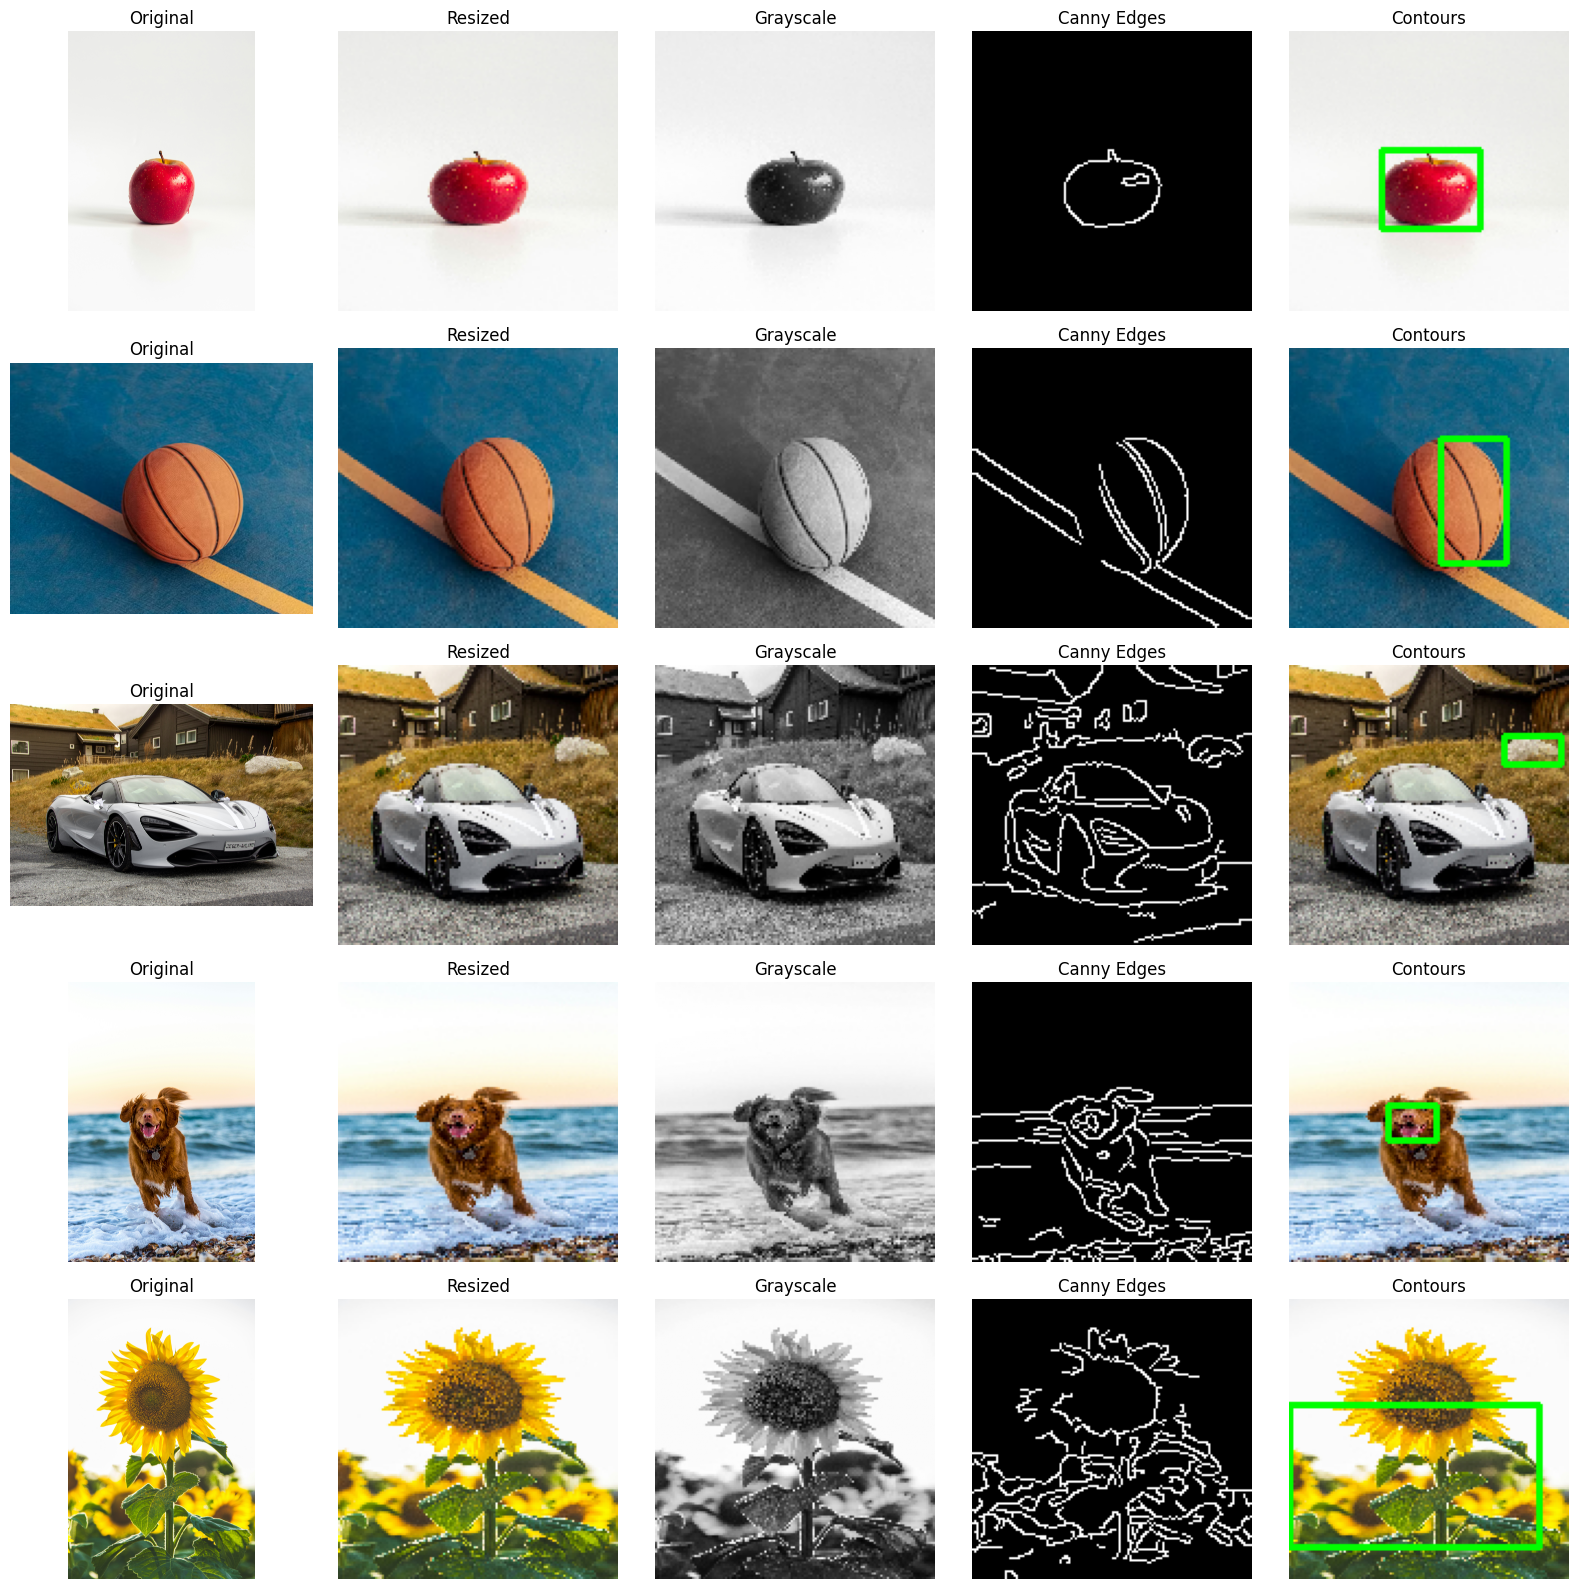

In [97]:
fig, axes = plt.subplots(5, 5, figsize=(16, 16))

titles = [
    "Original",
    "Resized",
    "Grayscale",
    "Canny Edges",
    "Contours"
]

for i in range(5):
    name, original = images[i]
    resized = resized_images[i][1]
    gray = gray_images[i][1]
    edges = edge_images[i][1]
    contour = contour_images[i][1]

    results = [
        cv2.cvtColor(original, cv2.COLOR_BGR2RGB),
        cv2.cvtColor(resized, cv2.COLOR_BGR2RGB),
        gray,
        edges,
        cv2.cvtColor(contour, cv2.COLOR_BGR2RGB)
    ]

    for j in range(5):
        axes[i, j].imshow(results[j], cmap="gray" if j in [2, 3] else None)
        axes[i, j].set_title(titles[j])
        axes[i, j].axis("off")

    axes[i, 0].set_ylabel(name, fontsize=10)

plt.tight_layout()
plt.show()

## Save the processed images

In [98]:
os.makedirs("output_images", exist_ok=True)

for name, image in resized_images:
    cv2.imwrite(f"output_images/resized_{name}", image)

for name, image in gray_images:
    cv2.imwrite(f"output_images/gray_{name}", image)

for name, image in edge_images:
    cv2.imwrite(f"output_images/edges_{name}", image)

for name, image in contour_images:
    cv2.imwrite(f"output_images/contours_{name}", image)

print("All processed images saved in output_images folder.")

All processed images saved in output_images folder.


### Conclusion

In this practical, I used OpenCV to process five images. I loaded the images, resized them to 128 × 128 pixels, converted them to grayscale, applied Gaussian blur, detected edges using the Canny algorithm, and identified contours. I displayed the results in a 5 × 5 grid and saved the processed images in the `output_images` folder.

This practical helped me understand basic image processing techniques and how OpenCV can be used in computer vision applications.

# Task 3: CNN Image Classification Using CIFAR-10

## Objective
Build a Convolutional Neural Network (CNN) to classify images into 10 different categories using the CIFAR-10 dataset.

## Workflow
1. Load the CIFAR-10 dataset.
2. Select 20,000 training images and 4,000 test images.
3. Normalize pixel values.
4. Display sample images.
5. Build and train a CNN model.
6. Plot training and validation accuracy and loss.
7. Evaluate the model and generate a classification report.
8. Display 10 test predictions.
9. Save the trained model as `cnn_cifar10_model.h5`.

## Import libraries

In [68]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.utils import to_categorical

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")


TensorFlow version: 2.16.1
Libraries imported successfully!


## Load CIFAR-10 dataset

In [69]:

# Load the CIFAR-10 dataset
(X_train_full, y_train_full), (X_test_full, y_test_full) = cifar10.load_data()

print("Full training images:", X_train_full.shape)
print("Full training labels:", y_train_full.shape)
print("Full test images:", X_test_full.shape)
print("Full test labels:", y_test_full.shape)


Full training images: (50000, 32, 32, 3)
Full training labels: (50000, 1)
Full test images: (10000, 32, 32, 3)
Full test labels: (10000, 1)


## Select the required images

In [70]:

# Select the first 20,000 training images
X_train = X_train_full[:20000]
y_train = y_train_full[:20000]

# Select the first 4,000 test images
X_test = X_test_full[:4000]
y_test = y_test_full[:4000]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)


X_train: (20000, 32, 32, 3)
y_train: (20000, 1)
X_test: (4000, 32, 32, 3)
y_test: (4000, 1)


## Normalize the images

In [71]:

# Convert pixel values from 0–255 to 0–1
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())


Minimum pixel value: 0.0
Maximum pixel value: 1.0


## One-hot encode the labels

In [72]:

# Convert integer class labels into one-hot encoded vectors
y_train_cat = to_categorical(y_train, num_classes=10)
y_test_cat = to_categorical(y_test, num_classes=10)

print("Original label shape:", y_train.shape)
print("Encoded label shape:", y_train_cat.shape)
print("First encoded label:", y_train_cat[0])


Original label shape: (20000, 1)
Encoded label shape: (20000, 10)
First encoded label: [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]


## Display 10 sample images

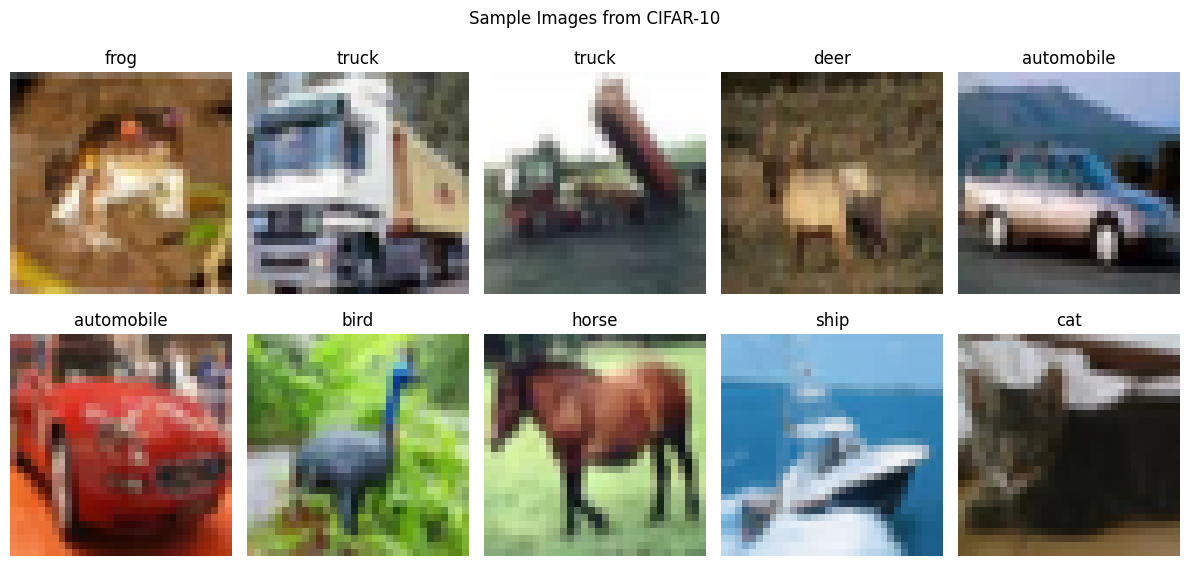

In [73]:

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i])
    label = int(y_train[i][0])
    plt.title(class_names[label])
    plt.axis("off")

plt.suptitle("Sample Images from CIFAR-10")
plt.tight_layout()
plt.show()


## Build the CNN model

In [74]:

model = Sequential([
    Conv2D(
        32,
        (3, 3),
        activation="relu",
        input_shape=(32, 32, 3)
    ),

    MaxPooling2D((2, 2)),

    Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),

    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(64, activation="relu"),

    Dense(10, activation="softmax")
])

model.summary()


c:\Users\hp\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 167,562 (654.54 KB)

 Trainable params: 167,562 (654.54 KB)

 Non-trainable params: 0 (0.00 B)

## Compile the CNN

In [75]:

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully!")


CNN model compiled successfully!


## Train the model

In [76]:

history = model.fit(
    X_train,
    y_train_cat,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)


Epoch 1/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.3468 - loss: 1.8097 - val_accuracy: 0.4405 - val_loss: 1.5726
Epoch 2/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.4819 - loss: 1.4516 - val_accuracy: 0.4920 - val_loss: 1.4087
Epoch 3/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.5304 - loss: 1.3188 - val_accuracy: 0.5315 - val_loss: 1.3405
Epoch 4/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.5686 - loss: 1.2257 - val_accuracy: 0.5485 - val_loss: 1.2852
Epoch 5/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.5970 - loss: 1.1515 - val_accuracy: 0.5600 - val_loss: 1.2406
Epoch 6/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 6s 22ms/step - accuracy: 0.6198 - loss: 1.0887 - val_accuracy: 0.5710 - val_loss: 1.2153
Epoch 7/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.6404 - loss: 1.0343 - val_accuracy: 0.5800 - val_loss: 1.1999
Epoch 8/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.6577 - loss: 0.9850 - val_acc

## Plot training and validation accuracy

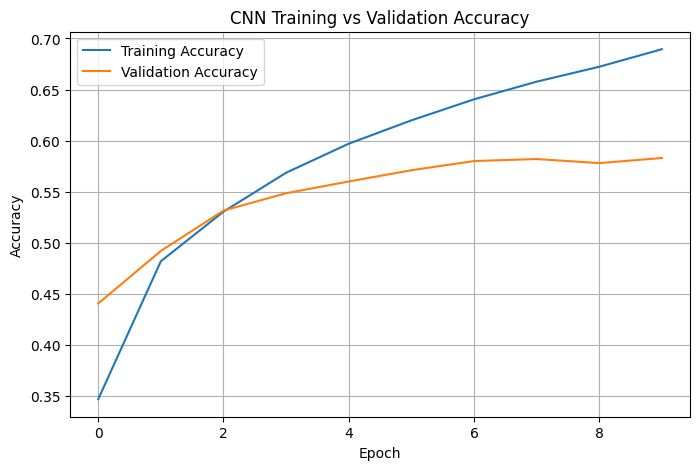

In [77]:

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


## Plot training and validation loss

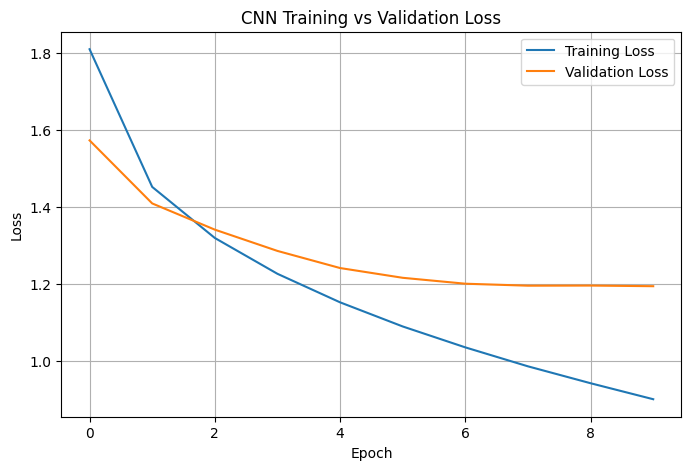

In [78]:

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("CNN Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


## Evaluate the model on test images

In [79]:

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test_cat,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy (%): {test_accuracy * 100:.2f}%")


125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6025 - loss: 1.1557
Test Loss: 1.1557
Test Accuracy: 0.6025
Test Accuracy (%): 60.25%


## Generate predictions

In [80]:

# Predict class probabilities
y_pred_prob = model.predict(X_test, verbose=1)

# Convert probabilities to predicted class IDs
y_pred = np.argmax(y_pred_prob, axis=1)

# Convert true labels to class IDs
y_true = y_test.flatten()

print("Actual labels:", y_true[:10])
print("Predicted labels:", y_pred[:10])


125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Actual labels: [3 8 8 0 6 6 1 6 3 1]
Predicted labels: [3 8 8 0 4 6 3 4 3 1]


## Classification report

In [81]:

print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(10)),
        target_names=class_names,
        zero_division=0
    )
)


              precision    recall  f1-score   support

    airplane       0.66      0.67      0.67       389
  automobile       0.79      0.72      0.75       392
        bird       0.55      0.42      0.48       426
         cat       0.41      0.42      0.41       389
        deer       0.45      0.60      0.51       400
         dog       0.55      0.42      0.47       388
        frog       0.84      0.53      0.65       396
       horse       0.63      0.70      0.66       397
        ship       0.58      0.90      0.70       408
       truck       0.76      0.63      0.69       415

    accuracy                           0.60      4000
   macro avg       0.62      0.60      0.60      4000
weighted avg       0.62      0.60      0.60      4000



## Confusion matrix

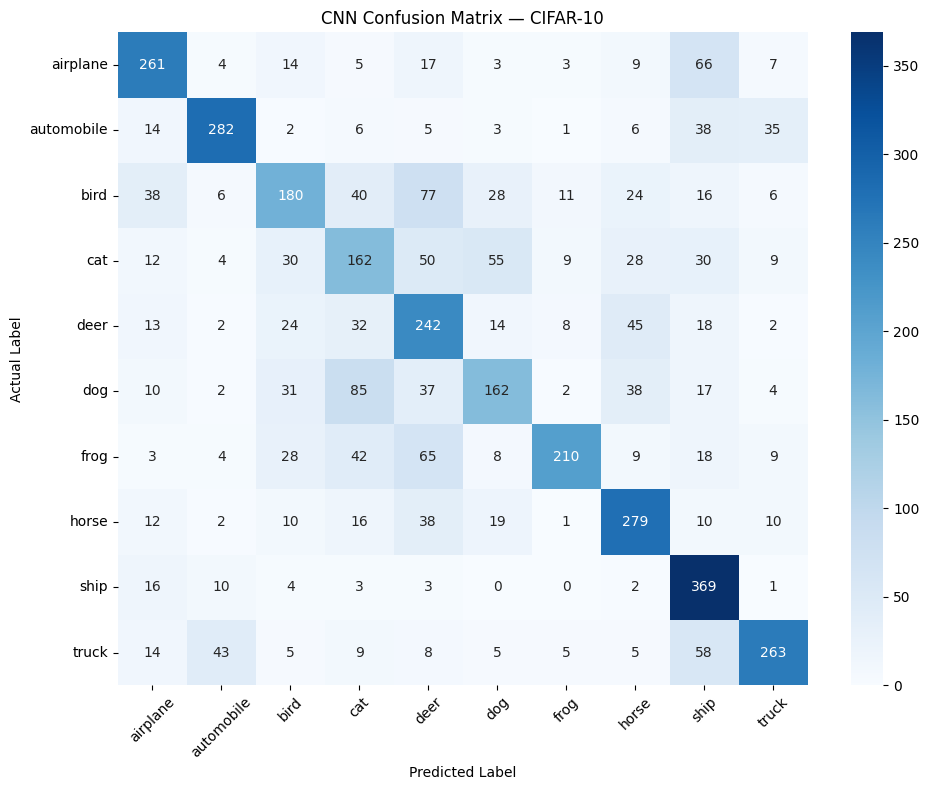

In [82]:

cm = confusion_matrix(y_true, y_pred, labels=list(range(10)))

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CNN Confusion Matrix — CIFAR-10")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## Display 10 test predictions

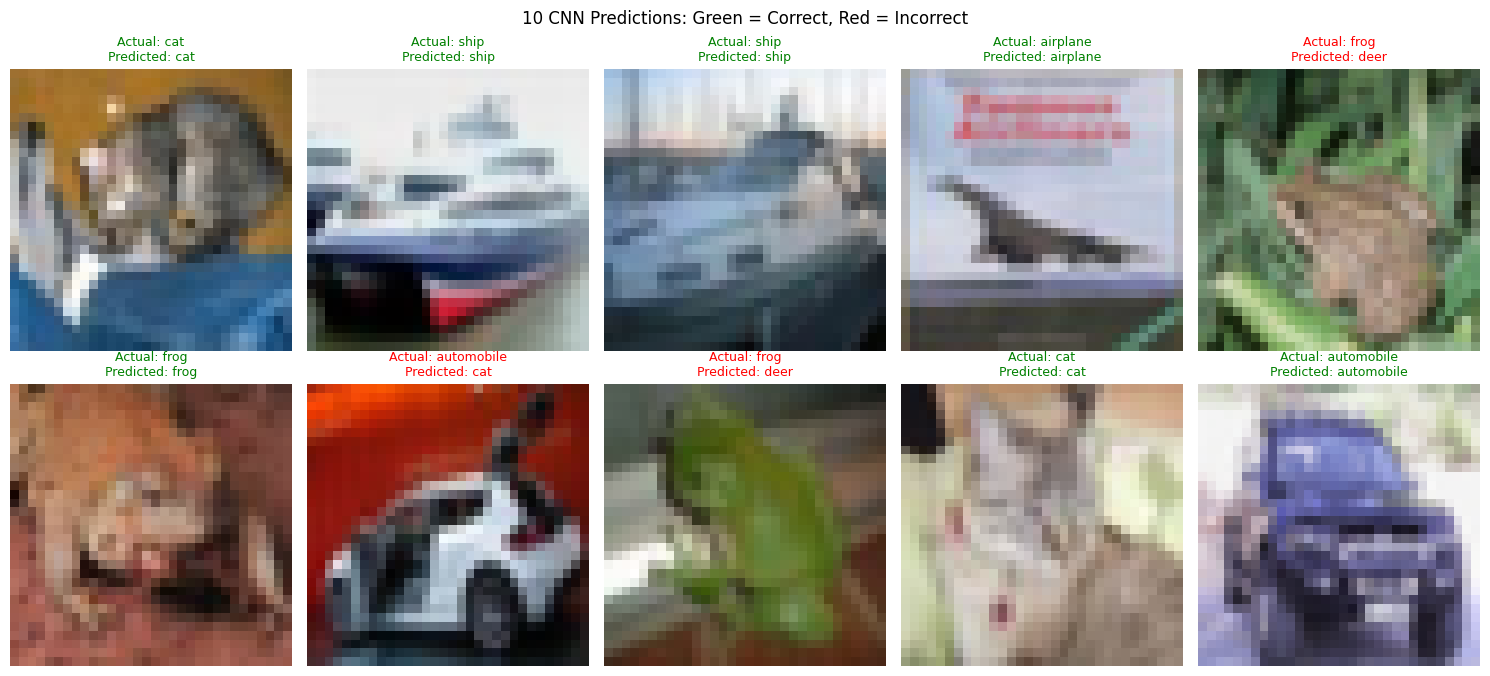

In [83]:

plt.figure(figsize=(15, 7))

for i in range(10):
    actual = int(y_true[i])
    predicted = int(y_pred[i])

    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i])

    color = "green" if actual == predicted else "red"

    plt.title(
        f"Actual: {class_names[actual]}\n"
        f"Predicted: {class_names[predicted]}",
        color=color,
        fontsize=9
    )
    plt.axis("off")

plt.suptitle("10 CNN Predictions: Green = Correct, Red = Incorrect")
plt.tight_layout()
plt.show()


## Save the trained model

In [84]:

model.save("cnn_cifar10_model.h5")

print("Model saved as cnn_cifar10_model.h5")


Model saved as cnn_cifar10_model.h5


## Task 3: Reflection

In this task, I built a Convolutional Neural Network (CNN) to classify images from the CIFAR-10 dataset into ten categories. I selected 20,000 training images and 4,000 test images and normalized the pixel values to the range 0–1.

The model used convolutional layers to learn image features, max-pooling layers to reduce spatial dimensions, a flattening layer, a dense layer, and a softmax output layer. I trained the model for ten epochs using the Adam optimizer and categorical cross-entropy loss.

I evaluated the model using test accuracy, classification metrics, a confusion matrix, and sample predictions. I also plotted training and validation accuracy and loss and saved the trained model as `cnn_cifar10_model.h5`.

**Conclusion:** CNNs are useful for image classification because they learn spatial patterns and visual features from images. Model performance depends on data quality, architecture, training duration, and hyperparameters.

# Task 4: Time-Series Prediction Using Simple RNN

## Objective
Build a Simple Recurrent Neural Network (RNN) to predict airline passenger numbers using historical monthly data.

## Workflow
1. Load the Airline Passengers dataset.
2. Explore and visualize the data.
3. Normalize passenger counts using MinMaxScaler.
4. Create sequences using the previous 12 months.
5. Split data into training and testing sets chronologically.
6. Build and train a SimpleRNN model.
7. Predict passenger counts and calculate RMSE.
8. Plot actual versus predicted passenger numbers.
9. Save the model as `rnn_airline_model.h5`.

## Import libraries

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.16.1
Libraries imported successfully!


## Load the dataset

In [48]:

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"

df = pd.read_csv(url)




In [49]:
print("Dataset shape:", df.shape)


Dataset shape: (144, 2)


In [50]:
print("\nFirst five rows:")
display(df.head())


First five rows:


,Month,Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


In [51]:
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Month       144 non-null    str  
 1   Passengers  144 non-null    int64
dtypes: int64(1), str(1)
memory usage: 2.4 KB


## Check missing values

In [53]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
Month         0
Passengers    0
dtype: int64


In [54]:
print("\nDuplicate rows:", df.duplicated().sum())



Duplicate rows: 0


In [55]:
print("\nSummary statistics:")
display(df["Passengers"].describe())


Summary statistics:


count    144.000000
mean     280.298611
std      119.966317
min      104.000000
25%      180.000000
50%      265.500000
75%      360.500000
max      622.000000
Name: Passengers, dtype: float64

## Visualize monthly passenger data

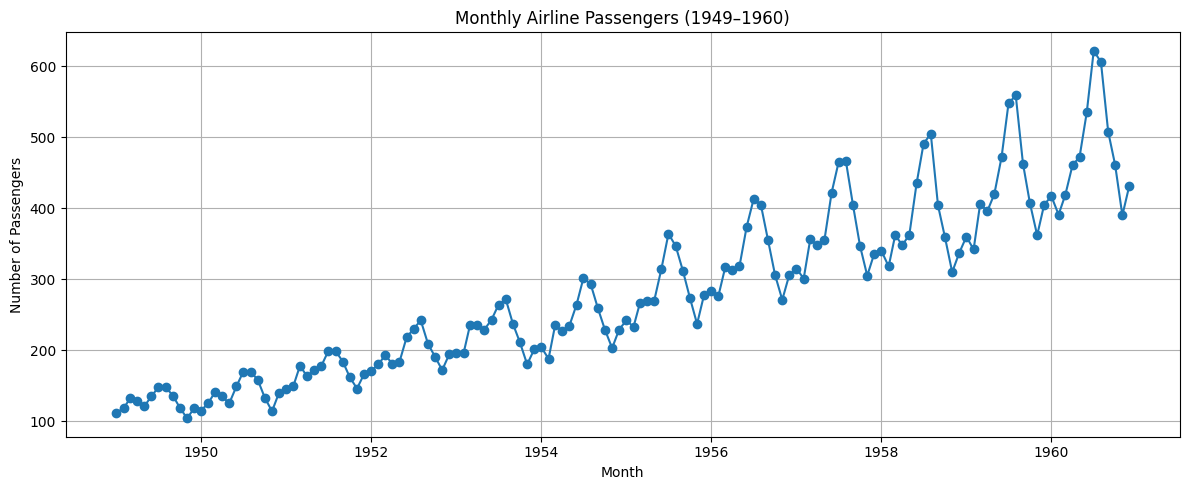

In [56]:

df["Month"] = pd.to_datetime(df["Month"])

plt.figure(figsize=(12, 5))
plt.plot(df["Month"], df["Passengers"], marker="o")

plt.title("Monthly Airline Passengers (1949–1960)")
plt.xlabel("Month")
plt.ylabel("Number of Passengers")
plt.grid(True)
plt.tight_layout()
plt.show()


## Normalize the data

In [57]:

passenger_data = df[["Passengers"]].values.astype("float32")

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(passenger_data)

print("Original passenger counts:", passenger_data[:5].flatten())
print("Scaled passenger counts:", scaled_data[:5].flatten())
print("Scaled minimum:", scaled_data.min())
print("Scaled maximum:", scaled_data.max())


Original passenger counts: [112. 118. 132. 129. 121.]
Scaled passenger counts: [0.01544401 0.02702703 0.05405405 0.04826255 0.03281853]
Scaled minimum: 0.0
Scaled maximum: 1.0


## Create sequences using the previous 12 months

In [58]:

def create_sequences(data, look_back=12):
    X, y = [], []

    for i in range(len(data) - look_back):
        X.append(data[i:i + look_back, 0])
        y.append(data[i + look_back, 0])

    return np.array(X), np.array(y)


look_back = 12

X, y = create_sequences(scaled_data, look_back)

print("X shape before reshape:", X.shape)
print("y shape:", y.shape)


X shape before reshape: (132, 12)
y shape: (132,)


## Reshape and split the data

In [59]:

# RNN input format: (samples, time steps, features)
X = X.reshape(X.shape[0], X.shape[1], 1)

# Use the first 80% for training and the remaining 20% for testing.
split_index = int(len(X) * 0.8)

X_train = X[:split_index]
X_test = X[split_index:]

y_train = y[:split_index]
y_test = y[split_index:]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (105, 12, 1)
X_test: (27, 12, 1)
y_train: (105,)
y_test: (27,)


## Build the SimpleRNN model

In [60]:

model = Sequential([
    SimpleRNN(
        50,
        activation="tanh",
        input_shape=(12, 1)
    ),
    Dense(1)
])

model.summary()


c:\Users\hp\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 50)             │         2,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,651 (10.36 KB)

 Trainable params: 2,651 (10.36 KB)

 Non-trainable params: 0 (0.00 B)

## Compile the model

In [61]:

model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

print("RNN model compiled successfully!")


RNN model compiled successfully!


## Train the RNN

In [62]:

history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=16,
    verbose=1
)


Epoch 1/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 0.0233
Epoch 2/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0099 
Epoch 3/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0056 
Epoch 4/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0033 
Epoch 5/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0025 
Epoch 6/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0022 
Epoch 7/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0017 
Epoch 8/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0016 
Epoch 9/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0013 
Epoch 10/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0012     
Epoch 11/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0011     
Epoch 12/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0011     
Epoch 13/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0010     
Epoch 14/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 9.8891e-04 
Epoch 15/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 9.5578e-04 
Epoch 16/5

## Plot training loss

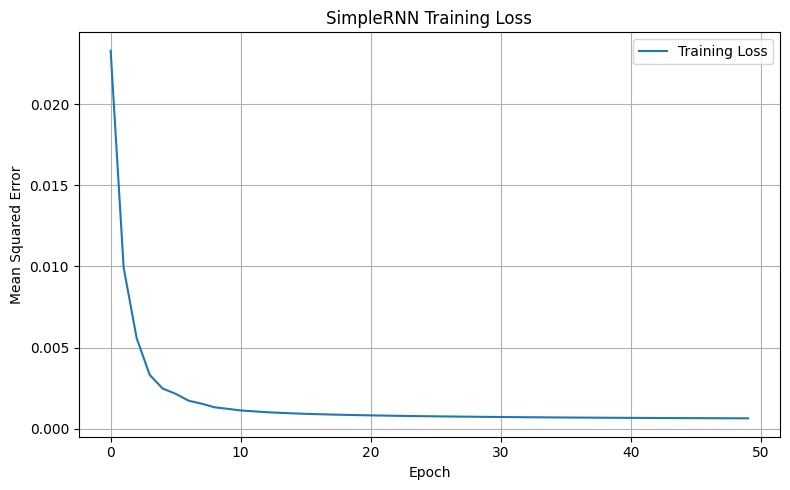

In [63]:

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")

plt.title("SimpleRNN Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


## Predict passenger counts

In [64]:

train_predictions_scaled = model.predict(X_train, verbose=0)
test_predictions_scaled = model.predict(X_test, verbose=0)

# Convert predictions back to passenger-count units
train_predictions = scaler.inverse_transform(train_predictions_scaled)
test_predictions = scaler.inverse_transform(test_predictions_scaled)

# Convert true labels back to passenger-count units
y_train_original = scaler.inverse_transform(y_train.reshape(-1, 1))
y_test_original = scaler.inverse_transform(y_test.reshape(-1, 1))

print("First 5 test actual values:")
print(y_test_original[:5].flatten())

print("\nFirst 5 test predictions:")
print(test_predictions[:5].flatten())


First 5 test actual values:
[359. 310. 337. 360. 342.]

First 5 test predictions:
[371.26782 328.20602 355.8343  353.7506  347.00058]


## Calculate RMSE

In [65]:

rmse = np.sqrt(
    mean_squared_error(
        y_test_original.flatten(),
        test_predictions.flatten()
    )
)

print(f"Test RMSE: {rmse:.2f} passengers")


Test RMSE: 40.57 passengers


## Plot actual versus predicted values

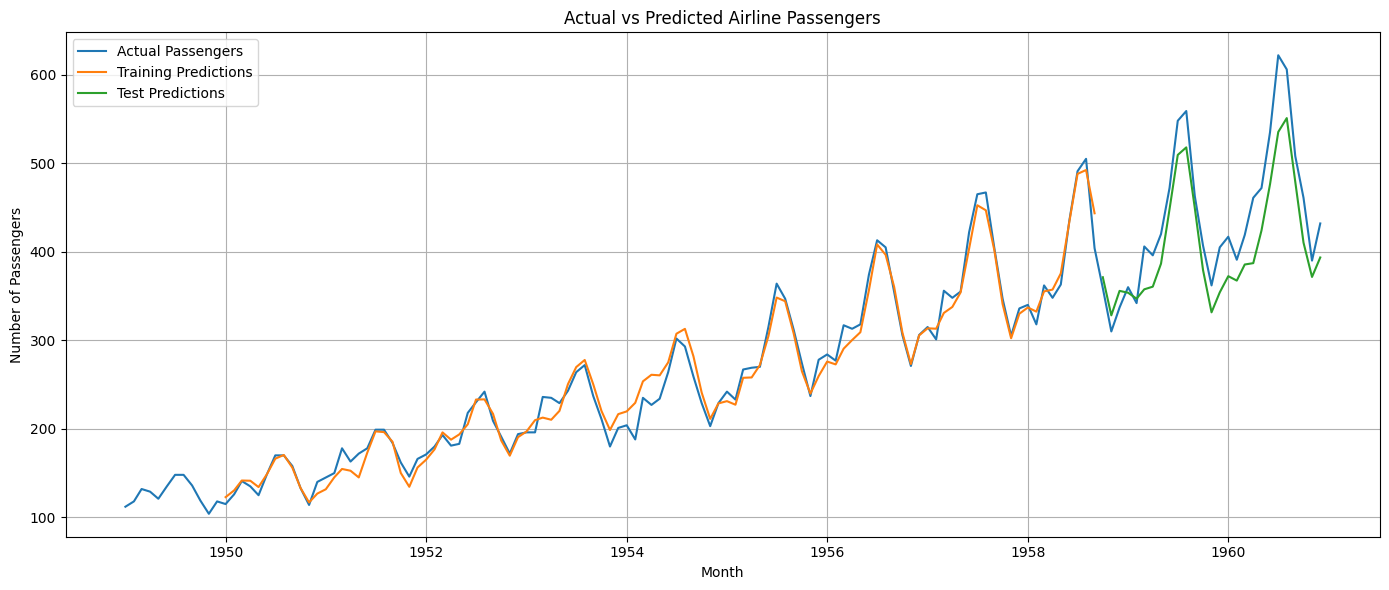

In [66]:

# Create arrays with gaps so the training and test predictions
# appear at their corresponding dates.
train_plot = np.full((len(df), 1), np.nan)
test_plot = np.full((len(df), 1), np.nan)

# Sequence target indices begin at look_back.
train_end = look_back + len(train_predictions)

train_plot[look_back:train_end] = train_predictions
test_plot[train_end:train_end + len(test_predictions)] = test_predictions

plt.figure(figsize=(14, 6))

plt.plot(
    df["Month"],
    passenger_data.flatten(),
    label="Actual Passengers"
)

plt.plot(
    df["Month"],
    train_plot.flatten(),
    label="Training Predictions"
)

plt.plot(
    df["Month"],
    test_plot.flatten(),
    label="Test Predictions"
)

plt.title("Actual vs Predicted Airline Passengers")
plt.xlabel("Month")
plt.ylabel("Number of Passengers")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


## Save the trained model

In [67]:

model.save("rnn_airline_model.h5")

print("Model saved as rnn_airline_model.h5")


Model saved as rnn_airline_model.h5


# Task 5: Transformer-Based Sentiment Analysis

## Objective
Use a pre-trained Transformer model to identify positive and negative sentiment in text.

## Workflow
1. Install the required libraries.
2. Create 25 sample sentences.
3. Load a pre-trained Hugging Face sentiment model.
4. Predict sentiment and confidence scores.
5. Create a Pandas DataFrame containing the results.
6. Evaluate predictions on 20 clearly positive or negative sentences.
7. Examine five ambiguous or neutral sentences.
8. Plot confidence scores.
9. Write a reflection on Transformer models and their limitations.

## Import libraries

In [33]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch

from transformers import pipeline

print("Libraries imported successfully!")
print("PyTorch version:", torch.__version__)


Libraries imported successfully!
PyTorch version: 2.14.0+cpu


## Create 25 sample sentences

In [34]:

sentences = [
    # 10 Positive sentences
    "I love learning machine learning and artificial intelligence.",
    "The movie was fantastic and very entertaining.",
    "The customer service was excellent.",
    "I am very happy with my new laptop.",
    "The food was delicious and fresh.",
    "The teacher explained everything clearly.",
    "This product is amazing and works perfectly.",
    "I had a wonderful experience at the hotel.",
    "The application is easy to use and very helpful.",
    "I am extremely satisfied with the results.",

    # 10 Negative sentences
    "I hate waiting for a long time.",
    "The movie was boring and disappointing.",
    "The customer service was terrible.",
    "My laptop is slow and keeps crashing.",
    "The food was cold and tasteless.",
    "The explanation was confusing and unclear.",
    "This product is poor quality and useless.",
    "I had a horrible experience at the hotel.",
    "The application is difficult to use.",
    "I am very disappointed with the results.",

    # 5 Neutral or ambiguous sentences
    "The meeting starts at ten in the morning.",
    "The package arrived yesterday.",
    "The movie was okay, but nothing special.",
    "The phone is expensive, but its camera is excellent.",
    "The food was good, although the service was slow."
]

true_sentiments = (
    ["POS"] * 10
    + ["NEG"] * 10
    + ["NEU"] * 5
)

print("Total sentences:", len(sentences))
print("Positive sentences:", true_sentiments.count("POS"))
print("Negative sentences:", true_sentiments.count("NEG"))
print("Neutral or ambiguous sentences:", true_sentiments.count("NEU"))


Total sentences: 25
Positive sentences: 10
Negative sentences: 10
Neutral or ambiguous sentences: 5


## Load the pre-trained Transformer model

In [46]:

model_name = "distilbert-base-uncased-finetuned-sst-2-english"

sentiment_pipeline = pipeline(
    task="sentiment-analysis",
    model=model_name
)

print("Pre-trained sentiment model loaded successfully!")


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Pre-trained sentiment model loaded successfully!


## Predict sentiment for all sentences

In [37]:

predictions = sentiment_pipeline(
    sentences,
    batch_size=8,
    truncation=True
)

for i, (sentence, prediction) in enumerate(
    zip(sentences, predictions),
    start=1
):
    print(f"{i}. {sentence}")
    print("   Predicted sentiment:", prediction["label"])
    print("   Confidence score:", round(prediction["score"], 4))
    print("-" * 70)


1. I love learning machine learning and artificial intelligence.
   Predicted sentiment: POSITIVE
   Confidence score: 0.9996
----------------------------------------------------------------------
2. The movie was fantastic and very entertaining.
   Predicted sentiment: POSITIVE
   Confidence score: 0.9999
----------------------------------------------------------------------
3. The customer service was excellent.
   Predicted sentiment: POSITIVE
   Confidence score: 0.9998
----------------------------------------------------------------------
4. I am very happy with my new laptop.
   Predicted sentiment: POSITIVE
   Confidence score: 0.9999
----------------------------------------------------------------------
5. The food was delicious and fresh.
   Predicted sentiment: POSITIVE
   Confidence score: 0.9999
----------------------------------------------------------------------
6. The teacher explained everything clearly.
   Predicted sentiment: POSITIVE
   Confidence score: 0.999
-----

## Create a results DataFrame

In [38]:

results_df = pd.DataFrame({
    "Sentence": sentences,
    "True_Sentiment": true_sentiments,
    "Predicted_Label": [p["label"] for p in predictions],
    "Confidence_Score": [p["score"] for p in predictions]
})

display(results_df)


,Sentence,True_Sentiment,Predicted_Label,Confidence_Score
0,I love learning machine learning and artificia...,POS,POSITIVE,0.999605
1,The movie was fantastic and very entertaining.,POS,POSITIVE,0.999887
2,The customer service was excellent.,POS,POSITIVE,0.999824
3,I am very happy with my new laptop.,POS,POSITIVE,0.999865
4,The food was delicious and fresh.,POS,POSITIVE,0.999883
5,The teacher explained everything clearly.,POS,POSITIVE,0.999018
6,This product is amazing and works perfectly.,POS,POSITIVE,0.999881
7,I had a wonderful experience at the hotel.,POS,POSITIVE,0.999882
8,The application is easy to use and very helpful.,POS,POSITIVE,0.999701
9,I am extremely satisfied with the results.,POS,POSITIVE,0.999550


## Evaluate the 20 clear-sentiment sentences

In [39]:
clear_results = results_df.iloc[:20].copy()

# Convert model labels into the format used by our expected labels
clear_results["Predicted_Sentiment"] = (
    clear_results["Predicted_Label"]
    .map({
        "POSITIVE": "POS",
        "NEGATIVE": "NEG"
    })
)


In [40]:
clear_results["Correct"] = (
    clear_results["True_Sentiment"]
    == clear_results["Predicted_Sentiment"]
)

correct_count = int(clear_results["Correct"].sum())
total_count = len(clear_results)
accuracy = correct_count / total_count * 100

print("Correct predictions:", correct_count)
print("Total clear-sentiment sentences:", total_count)
print(f"Accuracy on these 20 examples: {accuracy:.2f}%")

display(clear_results)


Correct predictions: 20
Total clear-sentiment sentences: 20
Accuracy on these 20 examples: 100.00%


,Sentence,True_Sentiment,Predicted_Label,Confidence_Score,Predicted_Sentiment,Correct
0,I love learning machine learning and artificia...,POS,POSITIVE,0.999605,POS,True
1,The movie was fantastic and very entertaining.,POS,POSITIVE,0.999887,POS,True
2,The customer service was excellent.,POS,POSITIVE,0.999824,POS,True
3,I am very happy with my new laptop.,POS,POSITIVE,0.999865,POS,True
4,The food was delicious and fresh.,POS,POSITIVE,0.999883,POS,True
5,The teacher explained everything clearly.,POS,POSITIVE,0.999018,POS,True
6,This product is amazing and works perfectly.,POS,POSITIVE,0.999881,POS,True
7,I had a wonderful experience at the hotel.,POS,POSITIVE,0.999882,POS,True
8,The application is easy to use and very helpful.,POS,POSITIVE,0.999701,POS,True
9,I am extremely satisfied with the results.,POS,POSITIVE,0.999550,POS,True


## Display the five neutral or ambiguous sentences

In [41]:

ambiguous_results = results_df.iloc[20:].copy()

print("Neutral or ambiguous sentence results:")
display(ambiguous_results)


Neutral or ambiguous sentence results:


,Sentence,True_Sentiment,Predicted_Label,Confidence_Score
20,The meeting starts at ten in the morning.,NEU,POSITIVE,0.967966
21,The package arrived yesterday.,NEU,POSITIVE,0.989624
22,"The movie was okay, but nothing special.",NEU,NEGATIVE,0.993532
23,"The phone is expensive, but its camera is exce...",NEU,POSITIVE,0.999496
24,"The food was good, although the service was slow.",NEU,POSITIVE,0.999277


## Plot confidence scores

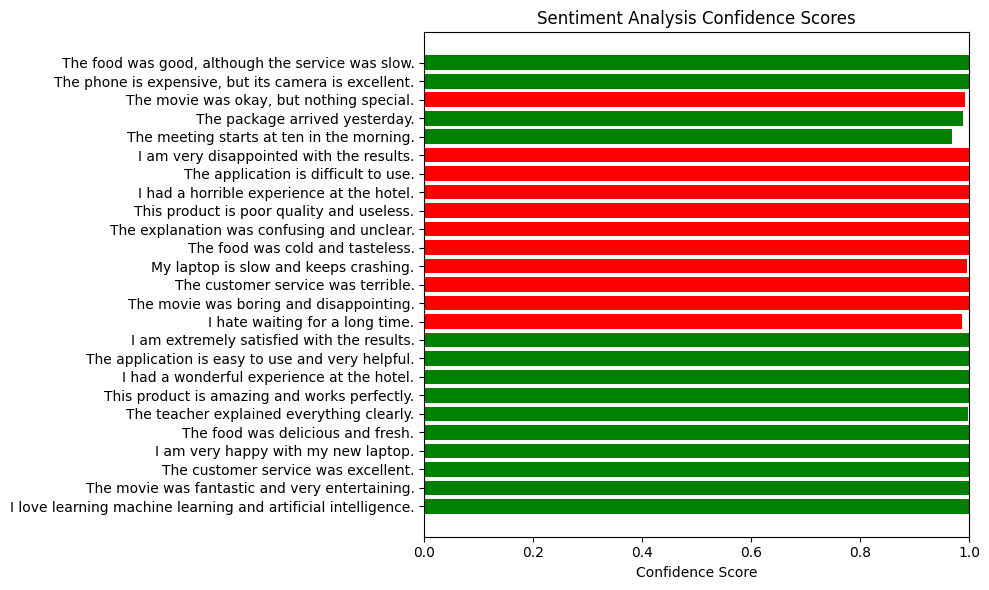

In [43]:
plt.figure(figsize=(10, 6))

colors = results_df["Predicted_Label"].map({
    "POSITIVE": "green",
    "NEGATIVE": "red"
})

plt.barh(results_df["Sentence"], results_df["Confidence_Score"], color=colors)

plt.xlabel("Confidence Score")
plt.title("Sentiment Analysis Confidence Scores")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

## Inspect low-confidence predictions

In [44]:
low_confidence = results_df.sort_values(
    "Confidence_Score",
    ascending=True
).head(5)

print("Five predictions with the lowest confidence scores:")
display(low_confidence)



Five predictions with the lowest confidence scores:


,Sentence,True_Sentiment,Predicted_Label,Confidence_Score
20,The meeting starts at ten in the morning.,NEU,POSITIVE,0.967966
10,I hate waiting for a long time.,NEG,NEGATIVE,0.986813
21,The package arrived yesterday.,NEU,POSITIVE,0.989624
22,"The movie was okay, but nothing special.",NEU,NEGATIVE,0.993532
13,My laptop is slow and keeps crashing.,NEG,NEGATIVE,0.996090


## Save the results

In [45]:

results_df.to_csv(
    "transformer_sentiment_results.csv",
    index=False
)

print("Results saved as transformer_sentiment_results.csv")


Results saved as transformer_sentiment_results.csv


## Task 5: Reflection

In this task, I implemented sentiment analysis using a pre-trained Transformer model from Hugging Face. I used DistilBERT fine-tuned on the SST-2 dataset to classify 25 sample sentences.

The dataset included ten positive sentences, ten negative sentences, and five neutral or ambiguous sentences. The model generated a predicted sentiment label and confidence score for each sentence. I stored the results in a Pandas DataFrame, evaluated predictions on the 20 clearly labeled examples, and plotted confidence scores.

I also inspected ambiguous sentences to understand the limitations of binary sentiment classification. The model always selects either positive or negative sentiment, even when a sentence is neutral or expresses mixed opinions.

**Conclusion:** Transformer models can understand contextual relationships in text and perform sentiment classification effectively. However, predictions can be affected by sarcasm, mixed sentiment, domain-specific language, and expressions that differ from the model's training data. Confidence scores should not be treated as guarantees of correctness.